In [87]:
import matplotlib.pyplot as plt
import pylab
import os
import numpy as np
from scipy.optimize import curve_fit

In [94]:
#Find file and store values

prename= r"/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/3-11-2022 Useable Sh0072 Spectra Measurment"

PT = 0.68
Strip = "F"
txtname = f"Sh0072_{Strip} PT {PT}"
#txtname = f"Sh0786_{Strip} PT {PT}"

file_path = os.path.join(prename)
name = os.path.join(prename,txtname+".txt")
filename = os.path.join(prename,txtname+".png")
print(name)

if os.path.exists(file_path):
    print(f"Path exists: {file_path}")
    pltfile = open(name, "r")
    nlines = len(open(name).readlines(  ))
    print(nlines)

    tarray = [0]*3
    ADC = [0]*nlines
    Nhits = [0]*nlines

    for i, x in enumerate(pltfile):
        if i == 0 or i == 1: #skip the first two lines
            continue
        tarray = x.strip().split(' ')
        ADC[i] = int(tarray[0])
        Nhits[i] = int(tarray[1])

        #print(f"{tarray[0]} , {tarray[1]}")

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/3-11-2022 Useable Sh0072 Spectra Measurment/Sh0072_F PT 0.68.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/3-11-2022 Useable Sh0072 Spectra Measurment
16384


[103.59126327 498.1339298   10.47219251]
Strip F Mean: 498.13392980264274
Strip F FWHM: 4.951%, Err: 0.048%
Strip F FWHM: 4.357 keV, Err: 0.042 keV
72	stripF	680.00	4.36	0.04



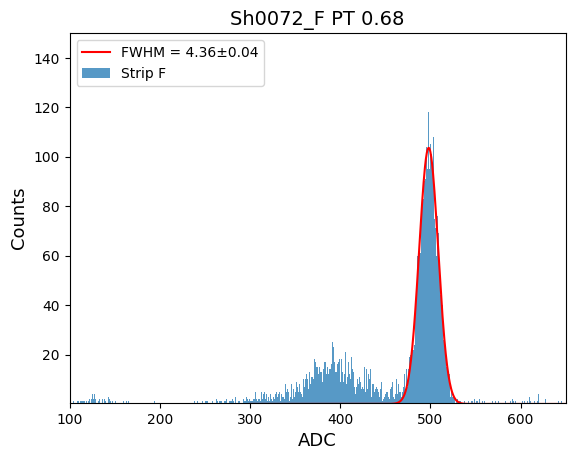

In [95]:
#Check the plot by just plotting one PT and doing one Gaussian fit

plot_min = 100
plot_max = 650
ymin = 0.5
ymax = 150

PT = 0.68
Strip = "F"
txtname = f"Sh0072_{Strip} PT {PT}"

#Gaussian fit, recall:
#  a: Some scaling factor to multiple the Gaussian by
#  b: Mean of the distribution
#  c: sigma of the distribution (square root of the variance), FWHM ~ 2.355*sigma
def gaussian(x, a, b, c):
    return a * np.exp(-((x - b)**2) / (2 * c**2))

y_scale = 1 #No scaling
title = txtname
plt.title(title,fontsize=14)
plt.xlabel("ADC",fontsize=13)
plt.ylabel("Counts",fontsize=13)
plt.ylim(ymin,ymax)
plt.xlim(plot_min,plot_max)

Nhits = np.array(Nhits)*y_scale

#Attempt to fit Gaussian:
Cshoulder_min = 250
Cshoulder_max = 400
Xray_min = Cshoulder_max
Xray_max = 550
Xray_peak = 88 #keV X-rays
dx = 0.5

Xray_xvals = np.arange(0.75*Xray_min,1.25*Xray_max,dx)
x_fitpars, x_mat = curve_fit(gaussian, ADC[Xray_min:Xray_max], Nhits[Xray_min:Xray_max], p0=[Xray_min, Xray_max, 5])
print(x_fitpars)
Xray_yvals = gaussian(Xray_xvals,x_fitpars[0],x_fitpars[1],x_fitpars[2])
x_sigma = np.abs(x_fitpars[2])
x_errors = np.sqrt(np.diag(x_mat))

#CS_xvals = np.arange(0.75*Cshoulder_min,1.25*Cshoulder_max,dx)
#Xray_xvals = np.arange(0.75*Xray_min,1.25*Xray_max,dx)

#CS_fitpars, CS_mat = curve_fit(gaussian, ADC[Cshoulder_min:Cshoulder_max], Nhits[Cshoulder_min:Cshoulder_max], p0=[Cshoulder_min, Cshoulder_max, 5])
#CS_yvals = gaussian(CS_xvals,CS_fitpars[0],CS_fitpars[1],CS_fitpars[2])
#plt.plot(CS_xvals,CS_yvals,alpha=0.75,color='red')

#fitpars, mat = curve_fit(gaussian, ADC[Cshoulder_min:Cshoulder_max], Nhits[Cshoulder_min:Cshoulder_max], p0=[Cshoulder_min, Cshoulder_max, 5])
print(f'Strip {Strip} Mean: {x_fitpars[1]}')
print(f'Strip {Strip} FWHM: {100*2.355*x_sigma/x_fitpars[1]:.3f}%, Err: {100*x_errors[2]/x_fitpars[1]:.3f}%')
print(f'Strip {Strip} FWHM: {2.355*x_sigma*Xray_peak/x_fitpars[1]:.3f} keV, Err: {x_errors[2]*Xray_peak/x_fitpars[1]:.3f} keV')

print(f"{det}\tstrip{Strip}\t{1000*PT:.2f}\t{2.355*x_sigma*Xray_peak/x_fitpars[1]:.2f}\t{x_errors[2]*Xray_peak/x_fitpars[1]:.2f}\n")

plt.bar(ADC[plot_min:plot_max], Nhits[plot_min:plot_max], 1, alpha=0.75,label=f"Strip {Strip}")
plt.plot(Xray_xvals,Xray_yvals,color='red',label=f'FWHM = {2.355*x_sigma*Xray_peak/x_fitpars[1]:.2f}\u00B1{x_errors[2]*Xray_peak/x_fitpars[1]:.2f}')
plt.legend(loc = 'upper left')
savename = os.path.join(file_path,f"{Strip}_{PT}_test.png")
plt.savefig(savename) #Save the file
plt.show()


/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/3-11-2022 Useable Sh0072 Spectra Measurment/Sh0072_F PT 0.68.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/3-11-2022 Useable Sh0072 Spectra Measurment
16384
Strip F Mean: 498.6145389219902
Strip F FWHM: 4.565%, Err: 0.083%
Strip F FWHM: 4.017 keV, Err: 0.073 keV


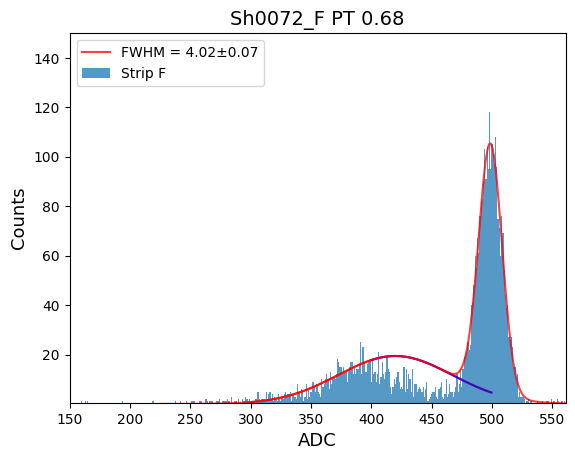

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/3-11-2022 Useable Sh0072 Spectra Measurment/Sh0072_F PT 1.35.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/3-11-2022 Useable Sh0072 Spectra Measurment
16384
Strip F Mean: 473.81813059870547
Strip F FWHM: 4.056%, Err: 0.027%
Strip F FWHM: 3.570 keV, Err: 0.024 keV


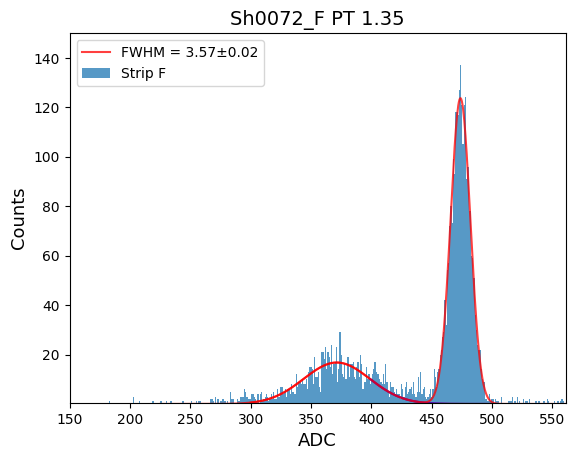

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/3-11-2022 Useable Sh0072 Spectra Measurment/Sh0072_F PT 3.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/3-11-2022 Useable Sh0072 Spectra Measurment
16384
Strip F Mean: 461.64339458311986
Strip F FWHM: 3.547%, Err: 0.030%
Strip F FWHM: 3.121 keV, Err: 0.027 keV


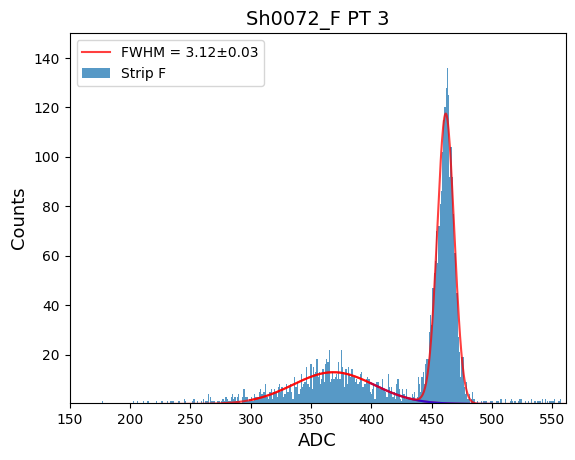

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/3-11-2022 Useable Sh0072 Spectra Measurment/Sh0072_F PT 4.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/3-11-2022 Useable Sh0072 Spectra Measurment
16384
Strip F Mean: 458.5666159676242
Strip F FWHM: 3.602%, Err: 0.029%
Strip F FWHM: 3.170 keV, Err: 0.025 keV


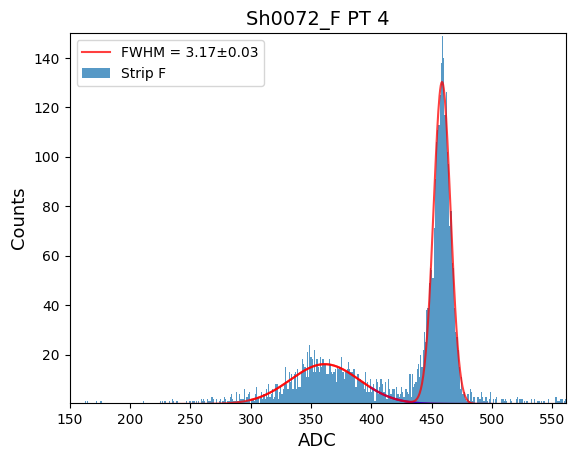

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/3-11-2022 Useable Sh0072 Spectra Measurment/Sh0072_F PT 5.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/3-11-2022 Useable Sh0072 Spectra Measurment
16384
Strip F Mean: 456.24135535215476
Strip F FWHM: 4.132%, Err: 0.037%
Strip F FWHM: 3.636 keV, Err: 0.032 keV


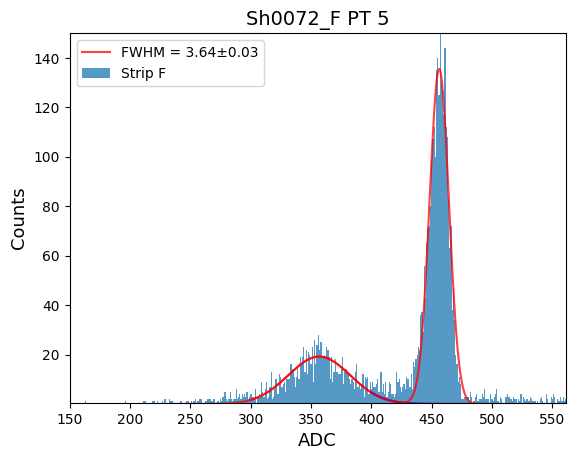

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/3-11-2022 Useable Sh0072 Spectra Measurment/Sh0072_F PT 8.0.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/3-11-2022 Useable Sh0072 Spectra Measurment
16384
Strip F Mean: 452.6979714400759
Strip F FWHM: 5.098%, Err: 0.045%
Strip F FWHM: 4.486 keV, Err: 0.039 keV


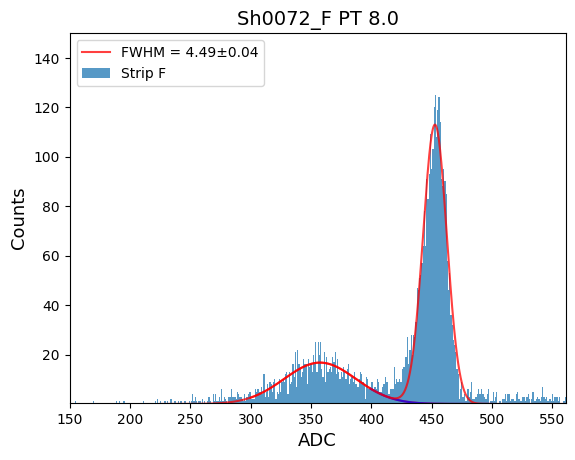

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/3-11-2022 Useable Sh0072 Spectra Measurment/Sh0072_F PT 13.1.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/3-11-2022 Useable Sh0072 Spectra Measurment
16384
Strip F Mean: 448.8730956439159
Strip F FWHM: 7.437%, Err: 0.069%
Strip F FWHM: 6.544 keV, Err: 0.061 keV


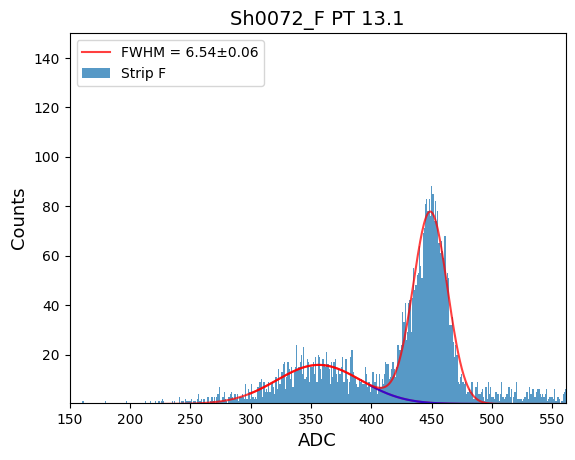

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/3-11-2022 Useable Sh0072 Spectra Measurment/Sh0072_F PT 21.6.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/3-11-2022 Useable Sh0072 Spectra Measurment
16384
Strip F Mean: 446.9474398991093
Strip F FWHM: 10.616%, Err: 0.136%
Strip F FWHM: 9.342 keV, Err: 0.120 keV


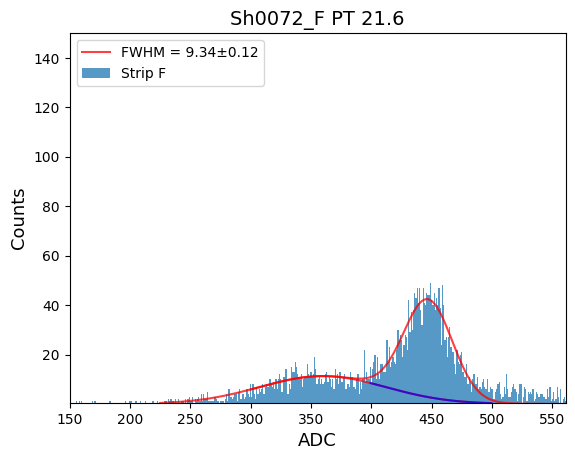

In [92]:
#Find file and store values

Peaking_Time_Array = [0.68,1.35,3,4,5,8.,13.1,21.6]
#Peaking_Time_Array = [0.5,1,2,3,4,5,7,9,11]
#Peaking_Time_Array = [0.68,1.35,3,4,5.4,8.1,13.5,21.6]
Strip = "F"

det = 72

plot_min = 100
plot_max = 600
ymin = 0.5
ymax = 150

#Gaussian fit, recall:
#  a: Some scaling factor to multiple the Gaussian by
#  b: Mean of the distribution
#  c: sigma of the distribution (square root of the variance), FWHM ~ 2.355*sigma
def gaussian(x, a, b, c):
    return a * np.exp(-((x - b)**2) / (2 * c**2))

#Attempt to fit Gaussian:
Cshoulder_min = 300
Cshoulder_max = 400
Xray_min = Cshoulder_max
Xray_max = 510
Xray_peak = 88 #keV X-rays
dx = 0.5

#X values for the Gaussian, more "smooth" than the actual histogram
xvals = np.arange(0.75*Cshoulder_min,1.25*Cshoulder_max,dx)
Xray_xvals = np.arange(0.75*Xray_min,1.25*Xray_max,dx)

datfile_name = os.path.join(file_path,f"{Strip}_summary.dat")
f = open(datfile_name,"w")
f.write("")
f.close()

for k in range(len(Peaking_Time_Array)):
    PT = Peaking_Time_Array[k]
    txtname = f"Sh0072_{Strip} PT {PT}"
    #txtname = f"Sh0786_{Strip} PT {PT}"

    file_path = os.path.join(prename)
    name = os.path.join(prename,txtname+".txt")
    filename = os.path.join(prename,f"{det}.png")
    print(name)

    if os.path.exists(file_path):
        print(f"Path exists: {file_path}")
        pltfile = open(name, "r")
        nlines = len(open(name).readlines(  ))
        print(nlines)

        tarray = [0]*3
        ADC = [0]*nlines
        Nhits = [0]*nlines

        for i, x in enumerate(pltfile):
            if i == 0 or i == 1: #skip the first two lines
                continue
            tarray = x.strip().split(' ')
            ADC[i] = int(tarray[0])
            Nhits[i] = int(tarray[1])


    fitpars, mat = curve_fit(gaussian, ADC[Cshoulder_min:Cshoulder_max], Nhits[Cshoulder_min:Cshoulder_max], p0=[Cshoulder_min, Cshoulder_max, 5])
    #print(f'Strip {Strip}:' + str(fitpars))

    y_scale = 1 #No scaling
    title = txtname
    plt.title(title,fontsize=14)
    plt.xlabel("ADC",fontsize=13)
    plt.ylabel("Counts",fontsize=13)
    plt.ylim(ymin,ymax)
    plt.xlim(Cshoulder_min*0.5,Xray_max*1.1)

    Nhits = np.array(Nhits)*y_scale

    yvals = gaussian(xvals,fitpars[0],fitpars[1],fitpars[2])
    plt.plot(xvals,yvals,alpha=0.75,color='red')

    x_fitpars, x_mat = curve_fit(gaussian, ADC[Xray_min:Xray_max], Nhits[Xray_min:Xray_max], p0=[Xray_min, Xray_max, 5])

    indices = np.where(xvals >= Xray_min-dx)[0] #Compton shoulder xvals where there is overlap with Xray range
    plt.plot(xvals[indices],yvals[indices],alpha=0.75,color='blue')

    Xray_yvals = gaussian(Xray_xvals,x_fitpars[0],x_fitpars[1],x_fitpars[2])

    Nhits_CS_Subtracted = np.zeros(Xray_max)
    for i in range(Xray_min,Xray_max):
        Nhits_CS_Subtracted[i] = Nhits[i] - gaussian(i, fitpars[0],fitpars[1],fitpars[2])

    CS_sub_fitpars, CS_sub_mat = curve_fit(gaussian, ADC[Xray_min:Xray_max], Nhits_CS_Subtracted[Xray_min:Xray_max], p0=[Xray_min,Xray_max, 5])
    Xray_yvals_CS_sub = gaussian(Xray_xvals, fitpars[0],fitpars[1],fitpars[2]) + gaussian(Xray_xvals,CS_sub_fitpars[0],CS_sub_fitpars[1],CS_sub_fitpars[2])
    CS_sub_errors = np.sqrt(np.diag(CS_sub_mat))
    CS_sub_sigma = np.abs(CS_sub_fitpars[2])

    Nhits_CS_Subtracted = np.zeros(Xray_max)
    for i in range(Xray_min,Xray_max):
        Nhits_CS_Subtracted[i] = Nhits[i] - gaussian(i, fitpars[0],fitpars[1],fitpars[2])

    print(f'Strip {Strip} Mean: {CS_sub_fitpars[1]}')
    print(f'Strip {Strip} FWHM: {100*2.355*CS_sub_sigma/CS_sub_fitpars[1]:.3f}%, Err: {100*CS_sub_errors[2]/CS_sub_fitpars[1]:.3f}%')
    print(f'Strip {Strip} FWHM: {2.355*CS_sub_sigma*Xray_peak/CS_sub_fitpars[1]:.3f} keV, Err: {CS_sub_errors[2]*Xray_peak/CS_sub_fitpars[1]:.3f} keV')

    f = open(datfile_name,"a")
    #f.write("test")
    f.write(f"{det}\tstrip{Strip}\t{1000*PT:.2f}\t{2.355*CS_sub_sigma*Xray_peak/CS_sub_fitpars[1]:.2f}\t{CS_sub_errors[2]*Xray_peak/CS_sub_fitpars[1]:.2f}\n")
    f.close()

    plt.bar(ADC[plot_min:plot_max], Nhits[plot_min:plot_max], 1, alpha=0.75,label=f"Strip {Strip}")
    plt.plot(Xray_xvals,Xray_yvals_CS_sub,alpha=0.75,color='red',label=f'FWHM = {2.355*CS_sub_sigma*Xray_peak/CS_sub_fitpars[1]:.2f}\u00B1{CS_sub_errors[2]*Xray_peak/CS_sub_fitpars[1]:.2f}')
    plt.legend(loc = 'upper left')
    savename = os.path.join(file_path,f"{Strip}_{PT}_test.png")
    plt.savefig(savename) #Save the file
    plt.show()


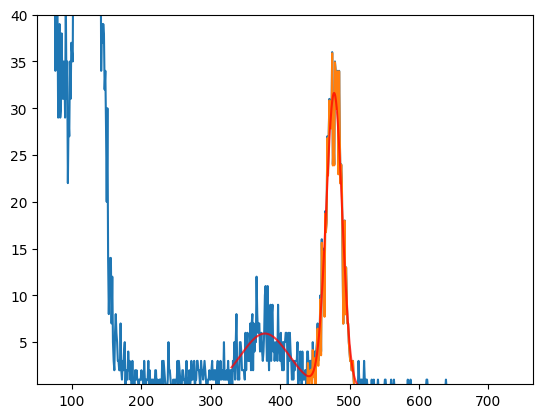

In [100]:
#Testing out the subtraction

Nhits_CS_Subtracted = np.zeros(Xray_max)
for i in range(Xray_min,Xray_max):
    Nhits_CS_Subtracted[i] = Nhits[i] - gaussian(i, fitpars[0],fitpars[1],fitpars[2])

CS_sub_fitpars, CS_sub_mat = curve_fit(gaussian, ADC[Xray_min:Xray_max], Nhits_CS_Subtracted[Xray_min:Xray_max], p0=[Xray_min,Xray_max, 5])
Xray_yvals_CS_sub = gaussian(Xray_xvals, fitpars[0],fitpars[1],fitpars[2]) + gaussian(Xray_xvals,CS_sub_fitpars[0],CS_sub_fitpars[1],CS_sub_fitpars[2])

plt.ylim(ymin,ymax)
plt.xlim(50,Xray_max*1.5)
plt.plot(Nhits)
plt.plot(Nhits_CS_Subtracted)
plt.plot(Xray_xvals,Xray_yvals_CS_sub,alpha=0.75,color='red')


Strip F1 Mean: 114.99431139360777
Strip F1 FWHM: 5.636%, Err: 0.095%
Strip F1 FWHM: 4.960 keV, Err: 0.084 keV


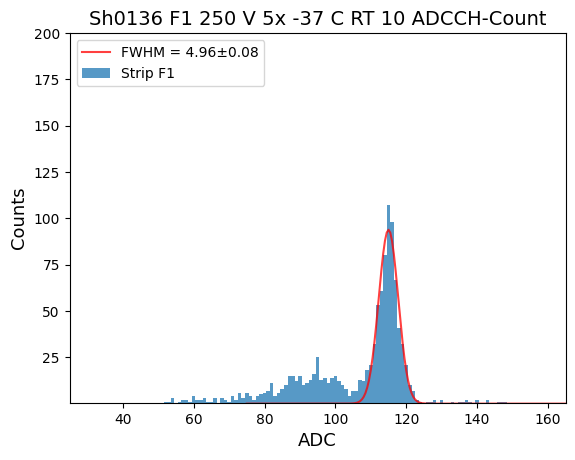

In [185]:
#Special case where "auto" fit isn't so good:
#No CS sub, just fit the peak!

prename= r"/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0136 Post-Dice A2 F1 E -37 C 250 V"

PT = 10
Strip = "F1"
txtname = f"Sh0136 {Strip} 250 V 5x -37 C RT {PT} ADCCH-Count"

plot_min = 50
plot_max = 150
ymin = 0.5
ymax = 200

#Gaussian fit, recall:
#  a: Some scaling factor to multiple the Gaussian by
#  b: Mean of the distribution
#  c: sigma of the distribution (square root of the variance), FWHM ~ 2.355*sigma
def gaussian(x, a, b, c):
    return a * np.exp(-((x - b)**2) / (2 * c**2))

Cshoulder_min = 50
Cshoulder_max = 100
Xray_min = Cshoulder_max
Xray_max = 150
Xray_peak = 88 #keV X-rays
dx = 0.5

#X values for the Gaussian, more "smooth" than the actual histogram
xvals = np.arange(0.75*Cshoulder_min,1.25*Cshoulder_max,dx)
Xray_xvals = np.arange(0.75*Xray_min,1.25*Xray_max,dx)

fitpars, mat = curve_fit(gaussian, ADC[Cshoulder_min:Cshoulder_max], Nhits[Cshoulder_min:Cshoulder_max], p0=[Cshoulder_min, Cshoulder_max, 5])
#print(f'Strip {Strip}:' + str(fitpars))

y_scale = 1 #No scaling
title = txtname
plt.title(title,fontsize=14)
plt.xlabel("ADC",fontsize=13)
plt.ylabel("Counts",fontsize=13)
plt.ylim(ymin,ymax)
plt.xlim(Cshoulder_min*0.5,Xray_max*1.1)

Nhits = np.array(Nhits)*y_scale

yvals = gaussian(xvals,fitpars[0],fitpars[1],fitpars[2])
#plt.plot(xvals,yvals,alpha=0.75,color='red')

x_fitpars, x_mat = curve_fit(gaussian, ADC[Xray_min:Xray_max], Nhits[Xray_min:Xray_max], p0=[Xray_min, Xray_max, 5])
x_errors = np.sqrt(np.diag(x_mat))

indices = np.where(xvals >= Xray_min-dx)[0] #Compton shoulder xvals where there is overlap with Xray range
#plt.plot(xvals[indices],yvals[indices],alpha=0.75,color='blue')

Xray_yvals = gaussian(Xray_xvals,x_fitpars[0],x_fitpars[1],x_fitpars[2])
x_sigma = np.abs(x_fitpars[2])

#plt.plot(Xray_xvals,Xray_yvals,alpha=0.75,color='blue')

print(f'Strip {Strip} Mean: {x_fitpars[1]}')
print(f'Strip {Strip} FWHM: {100*2.355*x_sigma/x_fitpars[1]:.3f}%, Err: {100*x_errors[2]/x_fitpars[1]:.3f}%')
print(f'Strip {Strip} FWHM: {2.355*x_sigma*Xray_peak/x_fitpars[1]:.3f} keV, Err: {x_errors[2]*Xray_peak/x_fitpars[1]:.3f} keV')

plt.bar(ADC[plot_min:plot_max], Nhits[plot_min:plot_max], 1, alpha=0.75,label=f"Strip {Strip}")
plt.plot(Xray_xvals,Xray_yvals,alpha=0.75,color='red',label=f'FWHM = {2.355*x_sigma*Xray_peak/x_fitpars[1]:.2f}\u00B1{x_errors[2]*Xray_peak/x_fitpars[1]:.2f}')
plt.legend(loc = 'upper left')
savename = os.path.join(file_path,f"{Strip}_{PT}_non_auto_test.png")
plt.savefig(savename) #Save the file
plt.show()

In [201]:
#Find file and store values

prename= r"/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0136 Post-Dice A2 F1 E -37 C 250 V"

Peaking_Time_Array = [1,2,3,4,5,6,7,8,9,10]
Strip = "A2"

det = 136
plot_min = 50
plot_max = 150
ymin = 0.5
ymax = 200

#Gaussian fit, recall:
#  a: Some scaling factor to multiple the Gaussian by
#  b: Mean of the distribution
#  c: sigma of the distribution (square root of the variance), FWHM ~ 2.355*sigma
def gaussian(x, a, b, c):
    return a * np.exp(-((x - b)**2) / (2 * c**2))

Cshoulder_min = 50
Cshoulder_max = 100
Xray_min = Cshoulder_max
Xray_max = 150
Xray_peak = 88 #keV X-rays
dx = 0.5

#X values for the Gaussian, more "smooth" than the actual histogram
xvals = np.arange(0.75*Cshoulder_min,1.25*Cshoulder_max,dx)
Xray_xvals = np.arange(0.75*Xray_min,1.25*Xray_max,dx)


for k in range(len(Peaking_Time_Array)):
    PT = Peaking_Time_Array[k]
    txtname = f"Sh0136 {Strip} 250 V 5x -37 C RT {PT} ADCCH-Count"
    #txtname = f"Sh0786_{Strip} PT {PT}"

    file_path = os.path.join(prename)
    name = os.path.join(prename,txtname+".txt")
    filename = os.path.join(prename,txtname+".png")
    #print(name)

    if os.path.exists(file_path):
        #print(f"Path exists: {file_path}")
        pltfile = open(name, "r")
        nlines = len(open(name).readlines(  ))
        #print(nlines)

        tarray = [0]*3
        ADC = [0]*nlines
        Nhits = [0]*nlines

        for i, x in enumerate(pltfile):
            if i == 0 or i == 1: #skip the first two lines
                continue
            tarray = x.strip().split(' ')
            ADC[i] = int(tarray[0])
            Nhits[i] = int(tarray[1])


    fitpars, mat = curve_fit(gaussian, ADC[Cshoulder_min:Cshoulder_max], Nhits[Cshoulder_min:Cshoulder_max], p0=[Cshoulder_min, Cshoulder_max, 5])
    #print(f'Strip {Strip}:' + str(fitpars))

    y_scale = 1 #No scaling
    title = txtname
    #plt.title(title,fontsize=14)
    #plt.xlabel("ADC",fontsize=13)
    #plt.ylabel("Counts",fontsize=13)
    #plt.ylim(ymin,ymax)
    #plt.xlim(Cshoulder_min*0.5,Xray_max*1.1)

    Nhits = np.array(Nhits)*y_scale

    yvals = gaussian(xvals,fitpars[0],fitpars[1],fitpars[2])
    #plt.plot(xvals,yvals,alpha=0.75,color='red')

    x_fitpars, x_mat = curve_fit(gaussian, ADC[Xray_min:Xray_max], Nhits[Xray_min:Xray_max], p0=[Xray_min, Xray_max, 5])

    indices = np.where(xvals >= Xray_min-dx)[0] #Compton shoulder xvals where there is overlap with Xray range
    #plt.plot(xvals[indices],yvals[indices],alpha=0.75,color='blue')

    Xray_yvals = gaussian(Xray_xvals,x_fitpars[0],x_fitpars[1],x_fitpars[2])

    Nhits_CS_Subtracted = np.zeros(Xray_max)
    for i in range(Xray_min,Xray_max):
        Nhits_CS_Subtracted[i] = Nhits[i] - gaussian(i, fitpars[0],fitpars[1],fitpars[2])

    CS_sub_fitpars, CS_sub_mat = curve_fit(gaussian, ADC[Xray_min:Xray_max], Nhits_CS_Subtracted[Xray_min:Xray_max], p0=[Xray_min,Xray_max, 5])
    Xray_yvals_CS_sub = gaussian(Xray_xvals, fitpars[0],fitpars[1],fitpars[2]) + gaussian(Xray_xvals,CS_sub_fitpars[0],CS_sub_fitpars[1],CS_sub_fitpars[2])
    CS_sub_errors = np.sqrt(np.diag(CS_sub_mat))
    CS_sub_sigma = np.abs(CS_sub_fitpars[2])

    Nhits_CS_Subtracted = np.zeros(Xray_max)
    for i in range(Xray_min,Xray_max):
        Nhits_CS_Subtracted[i] = Nhits[i] - gaussian(i, fitpars[0],fitpars[1],fitpars[2])

    #print(f'Strip {Strip} Mean: {CS_sub_fitpars[1]}')
    #print(f'Strip {Strip} FWHM: {100*2.355*CS_sub_sigma/CS_sub_fitpars[1]:.3f}%, Err: {100*CS_sub_errors[2]/CS_sub_fitpars[1]:.3f}%')
    #print(f'Strip {Strip} FWHM: {2.355*CS_sub_sigma*Xray_peak/CS_sub_fitpars[1]:.3f} keV, Err: {CS_sub_errors[2]*Xray_peak/CS_sub_fitpars[1]:.3f} keV')

    #plt.bar(ADC[plot_min:plot_max], Nhits[plot_min:plot_max], 1, alpha=0.75,label=f"Strip {Strip}")
    #plt.plot(Xray_xvals,Xray_yvals_CS_sub,alpha=0.75,color='red',label=f'FWHM = {2.355*CS_sub_sigma*Xray_peak/CS_sub_fitpars[1]:.2f}\u00B1{CS_sub_errors[2]*Xray_peak/CS_sub_fitpars[1]:.2f}')
    print(f"{det}\tstrip{Strip}\t{1000*PT:.2f}\t{2.355*CS_sub_sigma*Xray_peak/CS_sub_fitpars[1]:.2f}\t{CS_sub_errors[2]*Xray_peak/CS_sub_fitpars[1]:.2f}")
    #plt.legend(loc = 'upper left')
    #savename = os.path.join(file_path,f"{Strip}_{PT}_test.png")
    #plt.savefig(savename) #Save the file
    #plt.show()


136	stripA2	1000.00	4.58	0.05
136	stripA2	2000.00	3.70	0.04
136	stripA2	3000.00	3.37	0.03
136	stripA2	4000.00	3.81	0.05
136	stripA2	5000.00	3.87	0.03
136	stripA2	6000.00	4.18	0.04
136	stripA2	7000.00	3.83	0.04
136	stripA2	8000.00	4.59	0.05
136	stripA2	9000.00	4.47	0.05
136	stripA2	10000.00	4.69	0.05


stripA2
stripF1
stripE


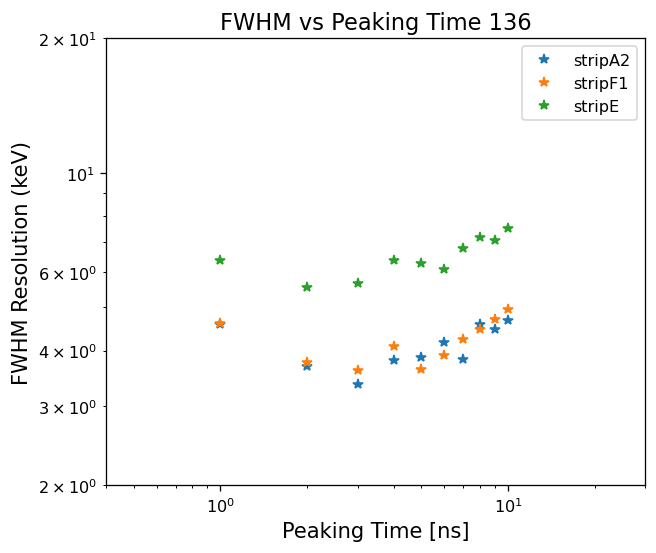

In [323]:
import pandas as pd
from collections import Counter

datfile = os.path.join(prename,'summary_KYfit.dat')
df = pd.read_csv(datfile, sep='\t', header=None)
nlines = len(df) #number of lines in the file
strip_list = list(set(df.head(nlines)[:][1])) #Individual strip names
nstrips = len(strip_list)

#What's the best way to do this? Associate each point with a strip/plot, something robust
#Check each line for the Strip name and put the numbers in the associated FWHM and errors array

#Below, use the .head()[column][row] function to pull specific values.
#[0] detector number, [1] strip letter, [2] PT in ns, [3] FWHM in keV, [4] error in FWHM
#print(df.head(nlines)[:][1])
#print(strip_list)

plt.figure(figsize=(6, 5),dpi=116)
plt.xscale('log')
plt.yscale('log')
plt.xlabel("Peaking Time [ns]",fontsize=13)
plt.ylabel("FWHM Resolution (keV)",fontsize=13)
plt.title(f'FWHM vs Peaking Time {det}',fontsize=14)
plt.ylim(2,20)
plt.xlim(0.4,30)

tarray = [0]*5 #Dat file structure has 5 lines

#Go line by line through the file, check the strip name, associate it with strip, right now I just want the FWHM and PT values!

for strp in strip_list:
    #Need to open this to be read each time!
    pltfile = open(datfile, "r")
    print(strp)
    FWHM = []
    PT = []
    #Go through the entire file
    for i, x in enumerate(pltfile):
        tarray = x.strip().split('\t')
        if(tarray[1] == strp):
            #print(f'PT: {tarray[2]} and FWHM {tarray[3]}')
            PT.append(float(tarray[2])/1000)
            FWHM.append(float(tarray[3]))
    plt.plot(PT,FWHM,'*',label=strp)
plt.legend()

    

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/9-15-2022 Sh0786 Spectra Measurement/Sh0786_H PT 1.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/9-15-2022 Sh0786 Spectra Measurement
16384
Strip H Mean: 477.732403720471
Strip H FWHM: 5.824%, Err: 0.093%
Strip H FWHM: 5.125 keV, Err: 0.082 keV


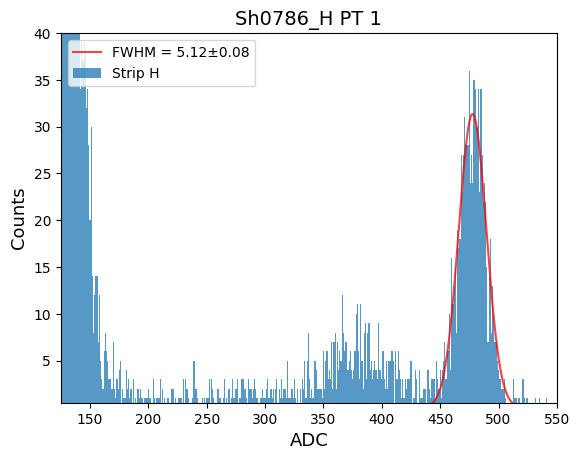

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/9-15-2022 Sh0786 Spectra Measurement/Sh0786_H PT 2.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/9-15-2022 Sh0786 Spectra Measurement
16384
Strip H Mean: 462.13970010671267
Strip H FWHM: 5.188%, Err: 0.069%
Strip H FWHM: 4.565 keV, Err: 0.061 keV


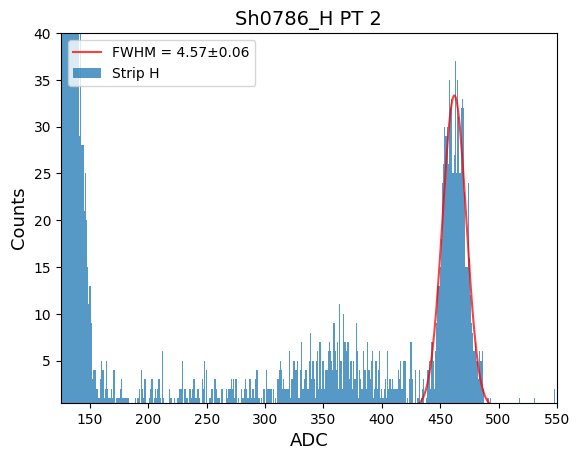

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/9-15-2022 Sh0786 Spectra Measurement/Sh0786_H PT 3.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/9-15-2022 Sh0786 Spectra Measurement
16384
Strip H Mean: 457.17100662834105
Strip H FWHM: 4.943%, Err: 0.063%
Strip H FWHM: 4.350 keV, Err: 0.055 keV


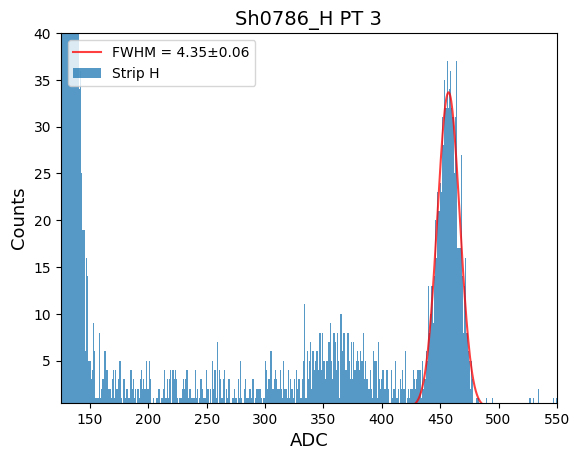

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/9-15-2022 Sh0786 Spectra Measurement/Sh0786_H PT 4.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/9-15-2022 Sh0786 Spectra Measurement
16384
Strip H Mean: 452.92795321552893
Strip H FWHM: 4.440%, Err: 0.077%
Strip H FWHM: 3.907 keV, Err: 0.068 keV


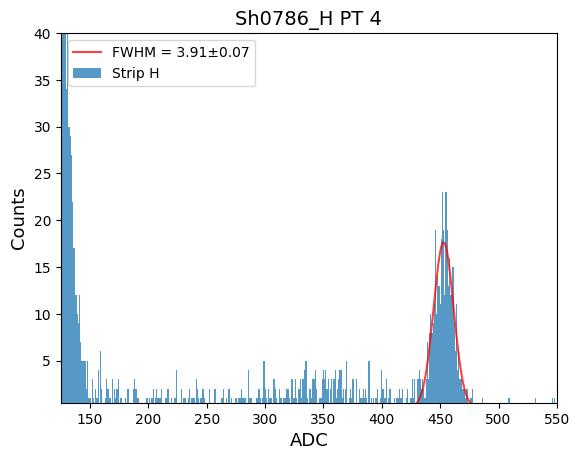

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/9-15-2022 Sh0786 Spectra Measurement/Sh0786_H PT 5.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/9-15-2022 Sh0786 Spectra Measurement
16384
Strip H Mean: 452.070985302431
Strip H FWHM: 4.396%, Err: 0.067%
Strip H FWHM: 3.869 keV, Err: 0.059 keV


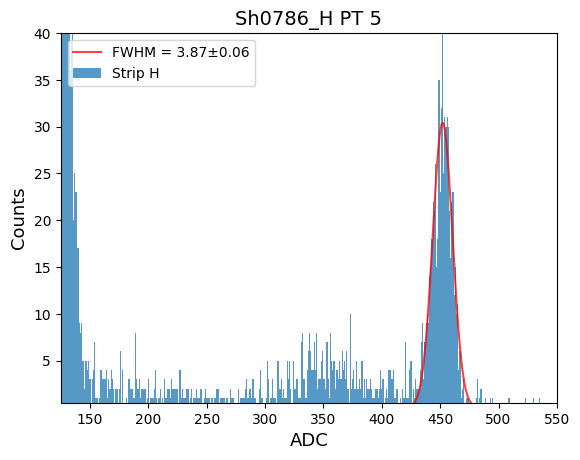

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/9-15-2022 Sh0786 Spectra Measurement/Sh0786_H PT 7.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/9-15-2022 Sh0786 Spectra Measurement
16384
Strip H Mean: 449.96825882737926
Strip H FWHM: 4.302%, Err: 0.070%
Strip H FWHM: 3.786 keV, Err: 0.061 keV


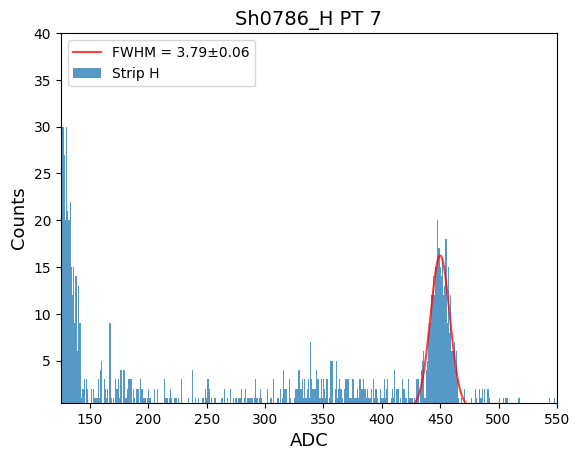

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/9-15-2022 Sh0786 Spectra Measurement/Sh0786_H PT 9.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/9-15-2022 Sh0786 Spectra Measurement
16384
Strip H Mean: 449.4355751050258
Strip H FWHM: 4.243%, Err: 0.072%
Strip H FWHM: 3.734 keV, Err: 0.063 keV


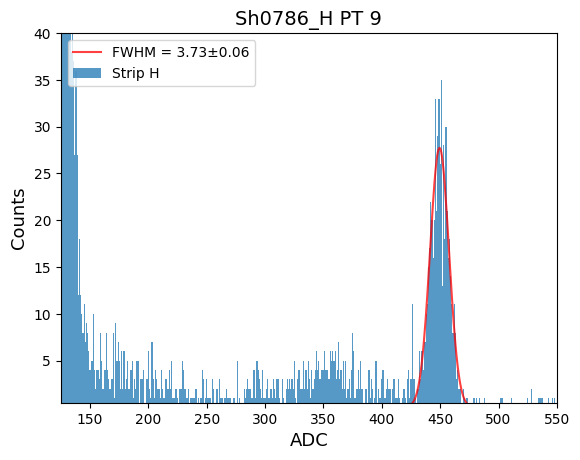

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/9-15-2022 Sh0786 Spectra Measurement/Sh0786_H PT 11.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/9-15-2022 Sh0786 Spectra Measurement
16384
Strip H Mean: 447.46002236946606
Strip H FWHM: 5.154%, Err: 0.081%
Strip H FWHM: 4.536 keV, Err: 0.072 keV


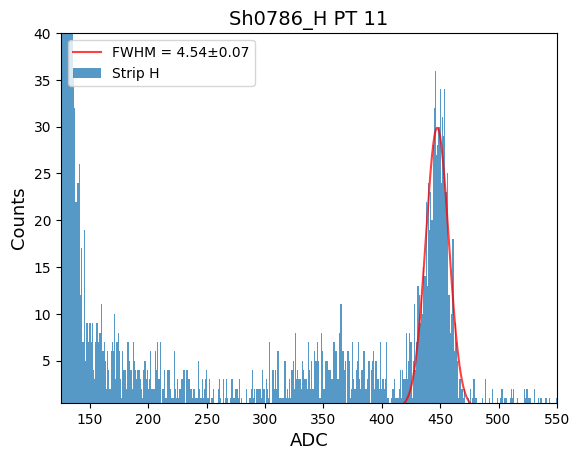

In [48]:
#Just the Gaussian!

prename= r"/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/9-15-2022 Sh0786 Spectra Measurement"


#Peaking_Time_Array = [1,1.5]
Peaking_Time_Array = [1,2,3,4,5,7,9,11]
Strip = "H"

plot_min = 100
plot_max = 600
ymin = 0.5
ymax = 40

#Gaussian fit, recall:
#  a: Some scaling factor to multiple the Gaussian by
#  b: Mean of the distribution
#  c: sigma of the distribution (square root of the variance), FWHM ~ 2.355*sigma
def gaussian(x, a, b, c):
    return a * np.exp(-((x - b)**2) / (2 * c**2))

y_scale = 1 #No scaling
title = txtname
plt.title(title,fontsize=14)
plt.xlabel("ADC",fontsize=13)
plt.ylabel("Counts",fontsize=13)
plt.ylim(ymin,ymax)
plt.xlim(Cshoulder_min*0.5,Xray_max*1.1)

Nhits = np.array(Nhits)*y_scale

#Attempt to fit Gaussian:
Cshoulder_min = 250
Cshoulder_max = 400
Xray_min = Cshoulder_max
Xray_max = 500
Xray_peak = 88 #keV X-rays
dx = 0.5

#X values for the Gaussian, more "smooth" than the actual histogram
xvals = np.arange(0.75*Cshoulder_min,1.25*Cshoulder_max,dx)
Xray_xvals = np.arange(0.75*Xray_min,1.25*Xray_max,dx)


for k in range(len(Peaking_Time_Array)):
    PT = Peaking_Time_Array[k]
    txtname = f"Sh0786_{Strip} PT {PT}"
    #txtname = f"Sh0786_{Strip} PT {PT}"

    file_path = os.path.join(prename)
    name = os.path.join(prename,txtname+".txt")
    filename = os.path.join(prename,txtname+".png")
    print(name)

    if os.path.exists(file_path):
        print(f"Path exists: {file_path}")
        pltfile = open(name, "r")
        nlines = len(open(name).readlines(  ))
        print(nlines)

        tarray = [0]*3
        ADC = [0]*nlines
        Nhits = [0]*nlines

        for i, x in enumerate(pltfile):
            if i == 0 or i == 1: #skip the first two lines
                continue
            tarray = x.strip().split(' ')
            ADC[i] = int(tarray[0])
            Nhits[i] = int(tarray[1])

    Xray_xvals = np.arange(0.75*Xray_min,1.25*Xray_max,dx)
    x_fitpars, x_mat = curve_fit(gaussian, ADC[Xray_min:Xray_max], Nhits[Xray_min:Xray_max], p0=[Xray_min, Xray_max, 5])
    Xray_yvals = gaussian(Xray_xvals,x_fitpars[0],x_fitpars[1],x_fitpars[2])
    x_errors = np.sqrt(np.diag(x_mat))
    x_sigma = np.abs(x_fitpars[2])
    
    y_scale = 1 #No scaling
    title = txtname
    plt.title(title,fontsize=14)
    plt.xlabel("ADC",fontsize=13)
    plt.ylabel("Counts",fontsize=13)
    plt.ylim(ymin,ymax)
    plt.xlim(Cshoulder_min*0.5,Xray_max*1.1)

    print(f'Strip {Strip} Mean: {x_fitpars[1]}')
    print(f'Strip {Strip} FWHM: {100*2.355*x_sigma/x_fitpars[1]:.3f}%, Err: {100*x_errors[2]/x_fitpars[1]:.3f}%')
    print(f'Strip {Strip} FWHM: {2.355*x_sigma*Xray_peak/x_fitpars[1]:.3f} keV, Err: {x_errors[2]*Xray_peak/x_fitpars[1]:.3f} keV')

    plt.bar(ADC[plot_min:plot_max], Nhits[plot_min:plot_max], 1, alpha=0.75,label=f"Strip {Strip}")
    plt.plot(Xray_xvals,Xray_yvals,alpha=0.75,color='red',label=f'FWHM = {2.355*x_sigma*Xray_peak/x_fitpars[1]:.2f}\u00B1{x_errors[2]*Xray_peak/x_fitpars[1]:.2f}')
    plt.legend(loc = 'upper left')
    savename = os.path.join(file_path,f"{Strip}_{PT}_test.png")
    plt.savefig(savename) #Save the file
    plt.show()

In [282]:
#Want to plot